# 06 · Text tokens, cross-attention, LoRA and text CFG

Trace tensor shapes through token conditioning, learn an explicitly synthetic attention exercise, and inspect the actual COCO results without confusing attention mechanics with semantic success.

**Prerequisites:** 04; matrix products and attention basics. No pretrained models needed for default cells.

**By the end:** Check token masking; distinguish spatial queries and text keys; train a toy attention task; inspect frozen/trainable boundaries and text CFG; assess real prompt failures.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. Cross-attention is a tensor operation

Image features `[B,C,H,W]` become $HW$ queries; text features `[B,L,D]`
become keys and values. With $h$ heads and $d=C/h$,
$$A=\operatorname{softmax}(QK^T/\sqrt d+M),\qquad O=AV.$$
Per-head $A$ has shape `[B,h,HW,L]`. The inspectable returned weights average
heads and reshape to `[B,H,W,L]`. The output is a residual image update.
Padding gets $-\infty$ logits. An all-masked sequence is rejected.
**Code:** `TextCrossAttention` in [text.py](../diffusion_lab/text.py).

In [2]:
from diffusion_lab.text import LowRankLinear, TextCrossAttention, TextUNet, text_guided_prediction

torch.manual_seed(91)
layer = TextCrossAttention(8, 6, heads=2)
features = torch.randn(1, 8, 4, 4)
tokens = torch.randn(1, 5, 6)
mask = torch.tensor([[True, True, True, True, False]])
output, weights = layer(features, tokens, mask, return_weights=True)
print(
    "features / tokens / output / weights:",
    features.shape,
    tokens.shape,
    output.shape,
    weights.shape,
)
assert (weights[..., 4] == 0).all()
torch.testing.assert_close(weights.sum(-1), torch.ones(1, 4, 4))
changed = tokens.clone()
changed[:, 4] = 1e6
torch.testing.assert_close(output, layer(features, changed, mask))
untrained_weights = weights.detach().clone()

features / tokens / output / weights: torch.Size([1, 8, 4, 4]) torch.Size([1, 5, 6]) torch.Size([1, 8, 4, 4]) torch.Size([1, 4, 4, 5])


## 2. Learn a tiny attention task and label its scope

We assign four arbitrary token vectors to four quadrants and train attention
weights with explicit quadrant supervision. This lets us see attention become
structured. **It does not train diffusion or prove word grounding**: the token
names below are artificial category names; no language encoder or image-caption data is used.
The real diffusion model receives supervision through the denoising objective,
not hand-labeled attention heatmaps.

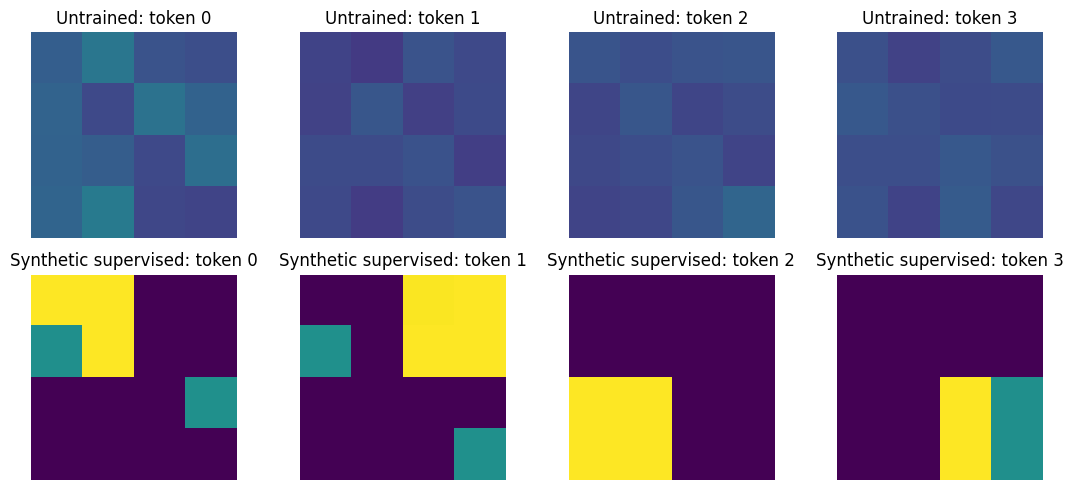

Toy attention CE before / after: 1.4015536308288574 0.13078109920024872


In [3]:
target_tokens = torch.tensor([[0, 0, 1, 1], [0, 0, 1, 1], [2, 2, 3, 3], [2, 2, 3, 3]])
optimizer = torch.optim.Adam(layer.parameters(), lr=0.025)
losses = []
for _step in range(200):
    _, weights = layer(features, tokens, mask, return_weights=True)
    selected = weights[0].gather(-1, target_tokens[..., None]).squeeze(-1)
    loss = -selected.clamp_min(1e-12).log().mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
_, trained_weights = layer(features, tokens, mask, return_weights=True)
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for row, (weight, title) in enumerate(
    [(untrained_weights, "Untrained"), (trained_weights.detach(), "Synthetic supervised")]
):
    for i in range(4):
        axes[row, i].imshow(weight[0, :, :, i], vmin=0, vmax=1, cmap="viridis")
        axes[row, i].set_title(f"{title}: token {i}")
        axes[row, i].axis("off")
plt.tight_layout()
plt.show()
print("Toy attention CE before / after:", losses[0], losses[-1])

## 3. Time-conditioned text U-Net integration

Our compact `TextUNet` inherits residual blocks, normalization modulation and
time embeddings from the image U-Net, inserting cross-attention at encoder,
middle and decoder levels. A text sequence is not reduced to one class ID.
The output is in the trainer's native epsilon or VP-v coordinate; it is not an RGB image when working in latents.
This random small network demonstrates shape/gradient integration, not generation quality.

In [4]:
network = TextUNet(
    text_dim=6,
    width=16,
    channel_mult=(1, 2),
    blocks_per_level=1,
    attention_levels=(),
    channels=4,
    time_embedding="positional",
    time_scale=1000.0,
)
latent = torch.randn(2, 4, 8, 8)
context = torch.randn(2, 5, 6)
valid = mask.repeat(2, 1)
prediction = network(latent, torch.tensor([0.2, 0.7]), context, valid)
assert prediction.shape == latent.shape
loss = (prediction - torch.randn_like(prediction)).square().mean()
loss.backward()
print(
    "Native latent prediction:",
    prediction.shape,
    "trainable parameters:",
    sum(p.numel() for p in network.parameters()),
)

Native latent prediction: torch.Size([2, 4, 8, 8]) trainable parameters: 190916


## 4. LoRA adapts a frozen projection

$$y=Wx+(\alpha/r)BAx.$$
$W$ stays frozen, $A$ starts random, $B$ starts zero. Initially the adapter
exactly preserves the base function. At the first update, $B$ can receive
gradient even though $A$ initially receives zero through $B$.
LoRA adapts a pretrained denoiser; a random compact denoiser is a separate experiment.
**Code:** `LowRankLinear`, `inject_lora` in [text.py](../diffusion_lab/text.py).

In [5]:
base = torch.nn.Linear(6, 8)
adapter = LowRankLinear(base, rank=2, alpha=2)
x = torch.randn(10, 6)
torch.testing.assert_close(adapter(x), base(x), atol=0, rtol=0)
original = base.weight.detach().clone()
optimizer = torch.optim.SGD([p for p in adapter.parameters() if p.requires_grad], lr=0.1)
adapter(x).square().mean().backward()
print(
    "Initial A / B gradient norms:",
    adapter.a.weight.grad.norm().item(),
    adapter.b.weight.grad.norm().item(),
)
optimizer.step()
torch.testing.assert_close(base.weight, original, atol=0, rtol=0)
print("Adapter changed function:", not torch.equal(adapter(x), base(x)))

Initial A / B gradient norms: 0.0 0.2542017698287964
Adapter changed function: True


## 5. Text CFG uses an encoded empty prompt

The null branch receives the text encoder's empty-prompt sequence (including
special tokens), **not an arbitrary all-zero tensor**. Mix native predictions
$y_u+w(y_c-y_u)$ before scheduler conversion. Caption dropout teaches the null
branch. Epsilon versus VP-v, latent scaling and scheduler beta convention
must agree between training and sampling.
**Code:** `text_guided_prediction` in [text.py](../diffusion_lab/text.py),
[text_train.py](../diffusion_lab/text_train.py), [text_evaluate.py](../diffusion_lab/text_evaluate.py).

In [6]:
# Synthetic contexts isolate the mixing identity; they are not real encoded prompts.
state = torch.randn(2, 4, 8, 8)
time = torch.ones(2) * 0.4
conditional_context = torch.ones(2, 3, 6)
synthetic_null = torch.zeros_like(conditional_context)


def predict(x, t, context):
    return x + context.mean((1, 2))[:, None, None, None]


for scale in [0.0, 1.0, 3.0]:
    guided, calls = text_guided_prediction(
        predict, state, time, conditional_context, synthetic_null, scale
    )
    torch.testing.assert_close(guided, state + scale)
    print("scale / branch calls:", scale, calls)

scale / branch calls: 0.0 1
scale / branch calls: 1.0 1
scale / branch calls: 3.0 2


## 6. Inspect real evidence, including failures

The following is the saved 100k-update **randomly initialized denoiser**, with
frozen pretrained VAE/text encoder, not an all-components-from-scratch model.
Prompt order: red bus, blue bus, two dogs, one dog; apples, oranges, cyclist
beside a red car, red car beside a cyclist. Vehicle color and fruit category
respond, while anatomy, counting and cyclist relationships fail visibly.
The held-out report uses 2,048 real/generated examples, 256px, CFG 7.5, 30 DDIM
steps. CLIP similarity is a coarse alignment diagnostic, not an anatomy/counting guarantee.

Actual COCO scratch-denoiser prompt contrasts, 100k updates


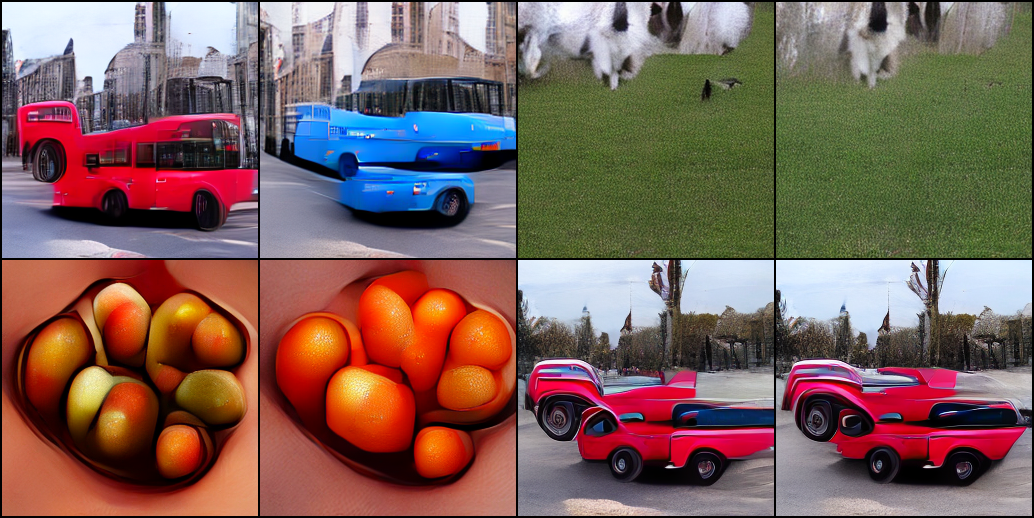

{'training_steps': 100000, 'generated_count': 2048, 'real_count': 2048, 'cfg_scale': 7.5, 'steps': 30, 'fid_2048': 53.63753890991211, 'inception_score_mean': 19.9285831451416, 'clip_cosine_mean': 0.22182586789131165}


In [7]:
saved_gallery(
    "assets/studies/scratch_refinement/text_step0100000_prompts/samples.png",
    "Actual COCO scratch-denoiser prompt contrasts, 100k updates",
)
report = json.loads(
    (project / "assets/studies/scratch_refinement/text_final_heldout/metrics.json").read_text()
)
keys = [
    "training_steps",
    "generated_count",
    "real_count",
    "cfg_scale",
    "steps",
    "fid_2048",
    "inception_score_mean",
    "clip_cosine_mean",
]
print({key: report[key] for key in keys})

## Exercises, answers and GPU extension

1. Why does masking padding affect keys but not remove image queries?
2. Does changing a pretrained VAE into a frozen component make the whole system trained from scratch?
3. Evaluate red/blue contrasts with shared noise, then counting and spatial relations separately.

<details><summary>Worked answers</summary>

1. Padding is a property of the text sequence. Every valid spatial location still needs to attend to valid text tokens.
2. No. State explicitly which components were randomly initialized and which were externally pretrained.
3. A mean CLIP increase can coexist with wrong counts or geometry. Use contrast diagnostics and direct visual inspection; split captions by image ID and disclose unknown external pretraining overlap.

</details>

Read [COCO commands and splits](../docs/24_text_conditioning.md) and
[scratch recipe](../configs/text_coco_scratch.yaml). On your cluster use
[text Slurm template](../slurm/train_coco_scratch.sbatch). These commands train
image-scale models separately; the notebook never silently starts a long GPU job.
**Continue:** [Interpolants/bridges](07_interpolants_transport_and_bridges.ipynb).
**Sources:** [Latent diffusion](https://arxiv.org/abs/2112.10752), [LoRA](https://arxiv.org/abs/2106.09685).